# Explore the redshift-zero 3D boxes

This notebook reads `Datasets/Grids_Mtot_IllustrisTNG_CV_128_z=0.0.npy`, explains its storage, selects one 3D cube, and displays a 3D structure view and 2D slices. Run cells from top to bottom. Figures are saved in `outputs/` as well as displayed below.

## 1. What is an `.npy` file?

An `.npy` file stores **one NumPy array** in binary form, with enough metadata to reconstruct its shape and numerical type. It is not a text table or a folder of separate cubes. A single array can have many dimensions. For multiple named arrays, NumPy provides `.npz`, a ZIP container of `.npy` files.

For this version-1.0 file, the layout is:

| Bytes | Contents |
|---|---|
| 0–5 | Magic signature `\x93NUMPY` |
| 6–7 | Format version: major 1, minor 0 |
| 8–9 | Little-endian 2-byte header length |
| 10–127 | Padded text header ending in a newline |
| 128 onward | Contiguous binary array values |

The header describes `shape`, `descr` (dtype), and `fortran_order`. Here it is:

```python
{'descr': '<f4', 'fortran_order': False, 'shape': (27, 128, 128, 128)}
```

- `<f4`: little-endian, 4-byte floating-point numbers (`float32`).
- `(27, 128, 128, 128)`: 27 cubes, each with 128 cells on each of three spatial axes.
- `fortran_order=False`: C order; the last index changes fastest on disk.

The numerical payload is `27 × 128³ × 4 = 226,492,416` bytes (216 MiB), plus a 128-byte preamble/header. For this file, the value at `data[b, i, j, k]` starts at byte `128 + 4 * (((b * 128 + i) * 128 + j) * 128 + k)`.

**Physical metadata:** the NPY header itself does not store field units. The owner has confirmed this file is unmodified CMD IllustrisTNG CV Mtot at redshift zero. Section 3 records the physical interpretation and checks the numerical scale. The spatial axes are named x, y, z by convention; spatial z is distinct from cosmological redshift.


In [28]:
from pathlib import Path
import struct
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Find the project from its folder, a subfolder, or its parent.
filename = 'Grids_Mtot_IllustrisTNG_CV_128_z=0.0.npy'
candidates = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next((p / 'Datasets' / filename for p in candidates
                  if (p / 'Datasets' / filename).is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f'Open this notebook from the project folder containing Datasets/{filename}.')
PROJECT_ROOT = DATA_PATH.parent.parent
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
print('Reading:', DATA_PATH)

# mmap_mode="r" gives read-only access without eagerly loading all 27 cubes.
data = np.load(DATA_PATH, mmap_mode='r', allow_pickle=False)
print('Shape:', data.shape, '| dtype:', data.dtype)
print(f'Payload: {data.nbytes / 2**20:.1f} MiB; file: {DATA_PATH.stat().st_size:,} bytes')
assert data.shape == (27, 128, 128, 128)
assert data.dtype == np.dtype('<f4')

Reading: /Users/amanda_437/lyman-alpha-project/Datasets/Grids_Mtot_IllustrisTNG_CV_128_z=0.0.npy
Shape: (27, 128, 128, 128) | dtype: float32
Payload: 216.0 MiB; file: 226,492,544 bytes


## 2. Inspect the actual header

NumPy normally handles the header for you. This cell reads it explicitly to connect the file layout to the loaded array. `np.load` is the preferred way to access the data.

In [29]:
with DATA_PATH.open('rb') as handle:
    magic = handle.read(6)
    version = tuple(handle.read(2))
    if version != (1, 0):
        raise ValueError('This demonstration expects NPY format version 1.0.')
    header_length = struct.unpack('<H', handle.read(2))[0]
    header = handle.read(header_length).decode('latin1')
    payload_offset = handle.tell()
print('Signature:', magic)
print('Version:', version)
print('Header length:', header_length)
print('Header:', header.strip())
print('Payload begins at byte:', payload_offset)
assert DATA_PATH.stat().st_size == payload_offset + data.nbytes

Signature: b'\x93NUMPY'
Version: (1, 0)
Header length: 118
Header: {'descr': '<f4', 'fortran_order': False, 'shape': (27, 128, 128, 128), }
Payload begins at byte: 128


## 3. Total matter density and physical coordinates

Confirmed source: CAMELS Multifield Dataset, IllustrisTNG, Cosmic Variance (CV), Mtot, 128³ grid, redshift 0. The file was downloaded without numerical transformations. Its 27 entries represent simulation realizations with different initial conditions.

Mtot is **total matter mass density**, with unit $U = \frac{M_\odot/h}{(\mathrm{Mpc}/h)^3} = \frac{h^2 M_\odot}{\mathrm{Mpc}^3}$. It is not the mass of a cell. We use $h=0.67$ and a box side of $25\,\mathrm{Mpc}/h$. The original cell width is $25/128=0.1953125\,\mathrm{Mpc}/h$ (about $0.29151\,\mathrm{Mpc}$). At redshift zero, comoving and proper lengths coincide.

The raw array values are interpreted in $U$. Convert density to $\frac{M_\odot}{\mathrm{Mpc}^3}$ by multiplying by $h^2$. Cell mass is $m_{\mathrm{cell}}=\rho_{\mathrm{tot}}\,\Delta x^3$, where $\Delta x=\frac{25}{128}\,\mathrm{Mpc}/h$; its unit is $M_\odot/h$; divide that mass by $h$ for $M_\odot$. No extra mass normalization is assumed.

The logarithmic display is $\log_{10}(\rho_{\mathrm{tot}}/U)$, a logarithm of a dimensionless numerical ratio. A color of $q$ therefore represents density $10^q \,U$. Nonpositive or nonfinite values are masked in this display. Shared 1st–99.5th percentile color limits clip colors only, not the source values. Percentiles count equal-volume cells, not fractions of total mass.

Set BOX_INDEX from 0 to 26 and rerun subsequent cells. The summary below calculates density statistics, cell volume, cell mass, and total grid mass from the selected cube. The corrected Mtot file has been checked: cube 0 has mean density approximately $8.32656 \cdot 10^{10} U$ and total mass $1.30103 \cdot 10^{15} \frac{M_\odot}{h}$. The magnitude check remains to help detect a future field or unit mismatch.

Source: [CMD field units and grid geometry](https://camels-multifield-dataset.readthedocs.io/en/latest/data.html).


In [42]:
BOX_INDEX = 0
LOG_SCALE = True
BOX_LENGTH = 25.0  # CMD box side in Mpc/h
HUBBLE_h = 0.67
DENSITY_UNIT = "(M_sun/h)/(Mpc/h)^3"
LENGTH_UNIT = r'\mathrm{Mpc}\,h^{-1}'
from IPython.display import display, Math
DENSITY_UNIT_TEX = r'\frac{M_\odot/h}{(\mathrm{Mpc}/h)^3}'
def tex_number(value):
    mantissa, exponent = f'{float(value):.6e}'.split('e')
    return rf'{float(mantissa):g} \times 10^{{{int(exponent)}}}'

if not 0 <= BOX_INDEX < data.shape[0]:
    raise ValueError('BOX_INDEX must be between 0 and 26.')
box = data[BOX_INDEX]  # A view of one 128³ cube, about 8 MiB.
finite = np.isfinite(box)
valid = finite & (box > 0) if LOG_SCALE else finite
if not valid.any():
    raise ValueError('No valid values for the requested display scale.')
field = np.full(box.shape, np.nan, dtype=np.float32)
if LOG_SCALE:
    np.log10(box, out=field, where=valid)
else:
    field[valid] = box[valid]
color_label = (rf'$\log_{{10}}\!\left(\rho_{{\mathrm{{tot}}}}/\left[{DENSITY_UNIT_TEX}\right]\right)$'
               if LOG_SCALE else rf'$\rho_{{\mathrm{{tot}}}}\;\left[{DENSITY_UNIT_TEX}\right]$')
vmin, vmax = np.percentile(field[valid], [1, 99.5])
if vmin == vmax:
    vmax = vmin + max(abs(float(vmin)) * 1e-6, 1e-6)
norm = Normalize(vmin=vmin, vmax=vmax, clip=True)
cmap = plt.get_cmap('inferno').copy()
cmap.set_bad('#c7c7c7')
N = box.shape[0]
length = float(N if BOX_LENGTH is None else BOX_LENGTH)
if not np.isfinite(length) or length <= 0:
    raise ValueError('BOX_LENGTH must be positive and finite.')
unit = 'voxel coordinate' if BOX_LENGTH is None else LENGTH_UNIT
spacing = length / N
centers = (np.arange(N) + 0.5) * spacing
raw = box[finite]
print(f'Cube {BOX_INDEX}: {box.shape}, {box.nbytes / 2**20:.1f} MiB')
display(Math(rf'\rho_{{\min}},\rho_{{\mathrm{{median}}}},\rho_{{\max}} = ({tex_number(raw.min())},\;{tex_number(np.median(raw))},\;{tex_number(raw.max())})\;{DENSITY_UNIT_TEX}'))
print(f'Masked cells: {box.size - np.count_nonzero(valid):,}')
display(Math(rf'{vmin:.3f} \leq ' + color_label.strip('$') + rf' \leq {vmax:.3f}'))
display(Math(rf'\Delta x={spacing:g}\,{unit}'))

# Derived physical quantities; float64 accumulation avoids float32 sum error.
cell_volume = spacing**3  # (Mpc/h)^3
mean_density = np.mean(raw, dtype=np.float64)
cell_mass = np.asarray(box, dtype=np.float64) * cell_volume  # M_sun/h
display(Math(rf'\bar\rho_{{\mathrm{{tot}}}}={tex_number(mean_density)}\;{DENSITY_UNIT_TEX}'))
display(Math(rf'\bar\rho_{{\mathrm{{tot}}}}={tex_number(mean_density * HUBBLE_h**2)}\;M_\odot\,\mathrm{{Mpc}}^{{-3}}'))
display(Math(rf'V_{{\mathrm{{cell}}}}={cell_volume:.8g}\;(\mathrm{{Mpc}}/h)^3'))
display(Math(rf'\Delta x={spacing / HUBBLE_h:.8g}\;\mathrm{{Mpc}}\quad(z=0)'))
display(Math(rf'm_{{\min}},m_{{\mathrm{{median}}}},m_{{\max}}=({tex_number(np.min(cell_mass[finite]))},\;{tex_number(np.median(cell_mass[finite]))},\;{tex_number(np.max(cell_mass[finite]))})\;M_\odot/h'))
if finite.all():
    total_mass = np.sum(cell_mass, dtype=np.float64)
    display(Math(rf'M_{{\mathrm{{box}}}}={tex_number(total_mass)}\;M_\odot/h={tex_number(total_mass / HUBBLE_h)}\;M_\odot'))
else:
    print('Total grid mass not reported: nonfinite density cells are present.')
if mean_density < 1e8 or mean_density > 1e13:
    print('METADATA CHECK: the mean density is far outside the expected cosmological matter-density scale in CMD units. Verify the original Mtot file identity before interpreting these derived masses. No rescaling has been applied.')


Cube 0: (128, 128, 128), 8.0 MiB


<IPython.core.display.Math object>

Masked cells: 0


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 4. Three perpendicular 2D slices

Each panel is one cell thick, not a sum or average through the box:

| Plane | Extraction | Horizontal / vertical axes |
|---|---|---|
| XY | `field[:, :, k]` | x / y |
| XZ | `field[:, j, :]` | x / z |
| YZ | `field[i, :, :]` | y / z |

NumPy places the first image index vertically, so `.T` puts the intended coordinate horizontally. `origin='lower'` puts coordinate zero at the bottom. All three panels use identical color limits.
Each slice retains density units $U$; it is not surface density. A line-of-sight integral would require summing raw density times the cell width and would have units $(M_{sun}/h)/(\mathrm{Mpc}/h)^2$.


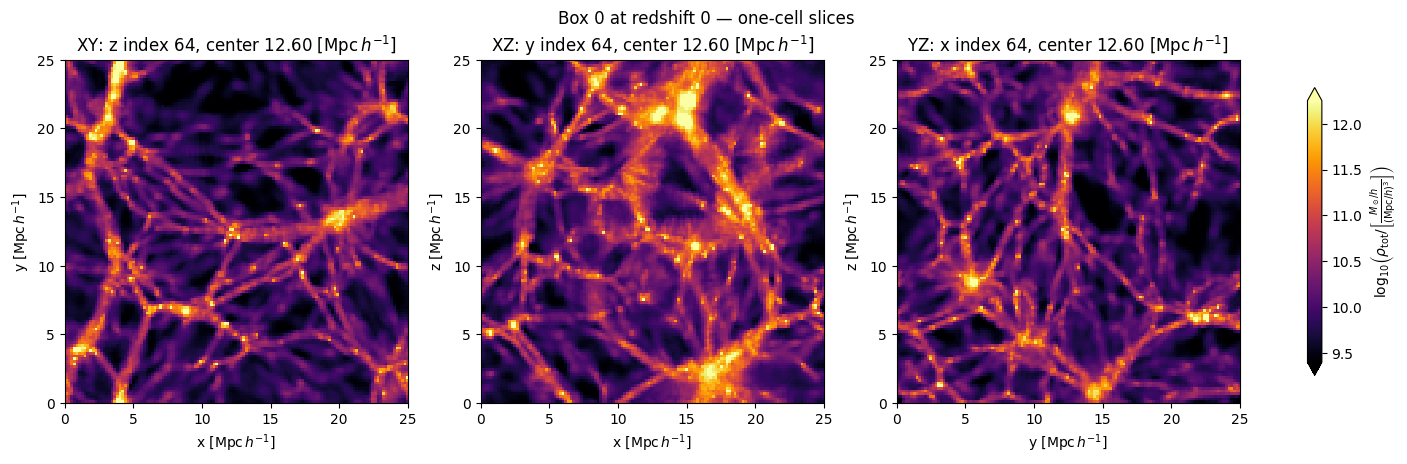

In [43]:
def plot_slices(i=N // 2, j=N // 2, k=N // 2):
    if not all(0 <= index < N for index in (i, j, k)):
        raise ValueError(f'Slice indices must lie between 0 and {N - 1}.')
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
    panels = [
        (field[:, :, k].T, 'x', 'y', f'XY: z index {k}, center {centers[k]:.2f} $[{unit}]$'),
        (field[:, j, :].T, 'x', 'z', f'XZ: y index {j}, center {centers[j]:.2f} $[{unit}]$'),
        (field[i, :, :].T, 'y', 'z', f'YZ: x index {i}, center {centers[i]:.2f} $[{unit}]$'),
    ]
    for ax, (image, xlabel, ylabel, title) in zip(axes, panels):
        artist = ax.imshow(np.ma.masked_invalid(image), origin='lower',
                           extent=(0, length, 0, length), cmap=cmap, norm=norm,
                           interpolation='nearest')
        ax.set(title=title, xlabel=f'{xlabel} $[{unit}]$', ylabel=f'{ylabel} $[{unit}]$')
    fig.colorbar(artist, ax=axes, label=color_label, shrink=0.8, extend='both')
    fig.suptitle(f'Box {BOX_INDEX} at redshift 0 — one-cell slices')
    return fig

fig = plot_slices()
fig.savefig(OUTPUT_DIR / f'box_{BOX_INDEX}_slices.png', dpi=160)
plt.show()

## 5. 3D structure view

The next view plots cell centers in the upper 1% of the valid values. This exposes spatial structure without hiding everything behind an opaque outer layer. It is a **thresholded point rendering**, not a rendering of every voxel or of individual particles. A reproducible sample limits the point count to 15,000. Change `HIGH_PERCENTILE` to reveal more or less structure; higher values show only the strongest peaks. A static notebook output has a fixed camera; the optional Plotly view below supports rotation.

<IPython.core.display.Math object>

20,972 cells pass the threshold; showing 15,000.


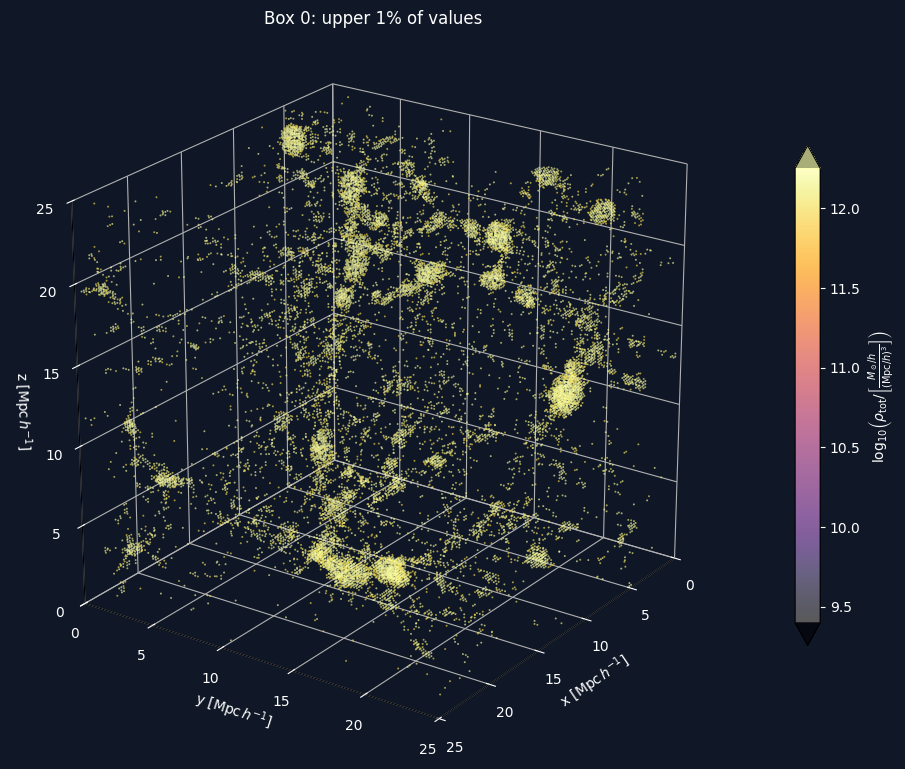

In [44]:
HIGH_PERCENTILE = 99.0
MAX_POINTS = 15_000
if not 0 <= HIGH_PERCENTILE <= 100:
    raise ValueError('HIGH_PERCENTILE must lie between 0 and 100.')
threshold = np.percentile(field[valid], HIGH_PERCENTILE)
rho_threshold = 10.0**threshold if LOG_SCALE else threshold
display(Math(rf'\rho_{{\mathrm{{threshold}}}}={tex_number(rho_threshold)}\;{DENSITY_UNIT_TEX}'))
indices = np.argwhere(valid & (field >= threshold))
selected_count = len(indices)
if selected_count > MAX_POINTS:
    rng = np.random.default_rng(42)
    indices = indices[rng.choice(selected_count, MAX_POINTS, replace=False)]
coordinates = (indices + 0.5) * spacing
values = field[tuple(indices.T)]

fig = plt.figure(figsize=(9, 8), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
# A dark background keeps the bright, high-value cells visible.
fig.patch.set_facecolor('#101827')
ax.set_facecolor('#101827')
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_pane_color((0.06, 0.09, 0.15, 1.0))
    axis.label.set_color('white')
ax.tick_params(colors='white')
points = ax.scatter(*coordinates.T, c=values, cmap=cmap, norm=norm,
                    s=2.0, alpha=0.65, linewidths=0, depthshade=False,
                    rasterized=True)
ax.set(xlim=(0, length), ylim=(0, length), zlim=(0, length),
       xlabel=f'x $[{unit}]$', ylabel=f'y $[{unit}]$', zlabel=f'z $[{unit}]$',
       title=f'Box {BOX_INDEX}: upper {100 - HIGH_PERCENTILE:g}% of values')
ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=23, azim=35)
ax.title.set_color('white')
colorbar = fig.colorbar(points, ax=ax, label=color_label, shrink=0.65, pad=0.08, extend='both')
colorbar.ax.tick_params(colors='white')
colorbar.ax.yaxis.label.set_color('white')
fig.savefig(OUTPUT_DIR / f'box_{BOX_INDEX}_3d.png', dpi=170)
print(f'{selected_count:,} cells pass the threshold; showing {len(indices):,}.')
plt.show()

## 6. Several slices along the spatial z axis

Following slices across the box helps distinguish isolated peaks from connected structure. These panels also use the same global color scale.

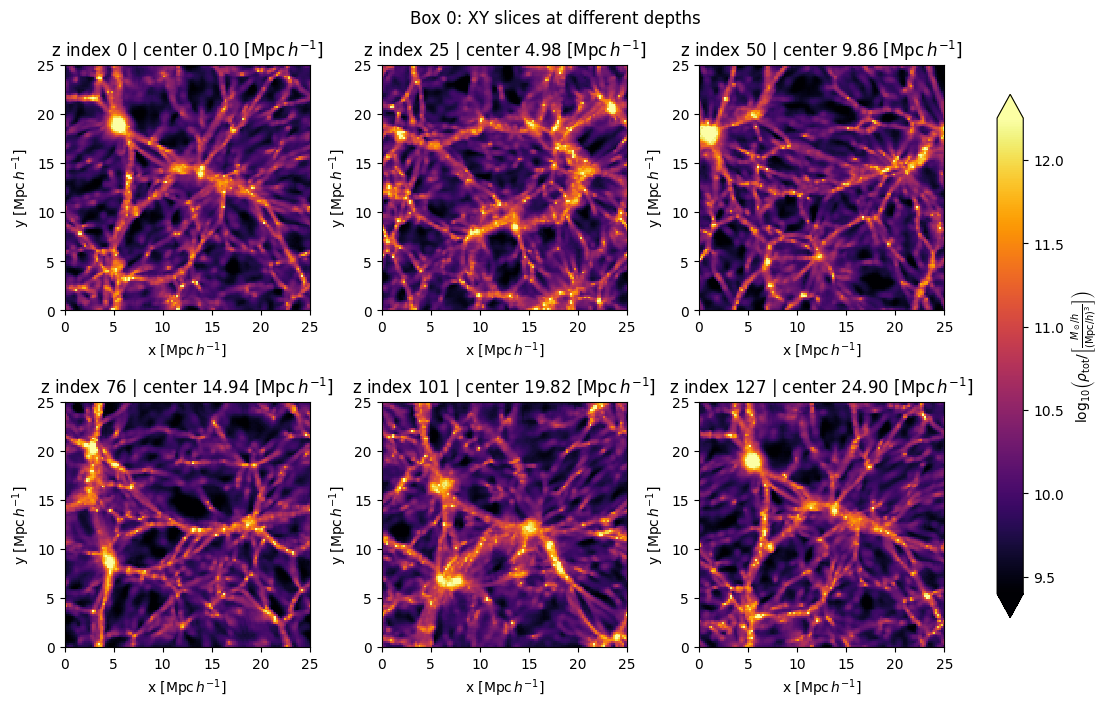

In [45]:
slice_indices = np.linspace(0, N - 1, 6, dtype=int)
fig, axes = plt.subplots(2, 3, figsize=(11, 7), constrained_layout=True)
for ax, k in zip(axes.flat, slice_indices):
    artist = ax.imshow(np.ma.masked_invalid(field[:, :, k].T), origin='lower',
                       extent=(0, length, 0, length), cmap=cmap, norm=norm,
                       interpolation='nearest')
    ax.set(title=f'z index {k} | center {centers[k]:.2f} $[{unit}]$',
           xlabel=f'x $[{unit}]$', ylabel=f'y $[{unit}]$')
fig.colorbar(artist, ax=axes.ravel().tolist(), label=color_label, shrink=0.85, extend='both')
fig.suptitle(f'Box {BOX_INDEX}: XY slices at different depths')
fig.savefig(OUTPUT_DIR / f'box_{BOX_INDEX}_slice_sequence.png', dpi=160)
plt.show()

## 7. Optional interactive slice controls

Requires `ipywidgets` and a notebook frontend that supports widgets. These controls update the three perpendicular slices; they do not change the selected cube. If controls do not appear, edit the indices in `plot_slices(i=64, j=64, k=64)` and rerun the static cell.

In [46]:
try:
    import ipywidgets as widgets
except ImportError:
    print('Optional: install ipywidgets to enable slice sliders.')
else:
    def show_slices(i, j, k):
        plot_slices(i, j, k)
        plt.show()
    slice_controls = widgets.interactive(
        show_slices,
        i=widgets.IntSlider(value=N // 2, min=0, max=N-1, description='x index', continuous_update=True),
        j=widgets.IntSlider(value=N // 2, min=0, max=N-1, description='y index', continuous_update=True),
        k=widgets.IntSlider(value=N // 2, min=0, max=N-1, description='z index', continuous_update=True),
    )
    from IPython.display import display
    display(slice_controls)

interactive(children=(IntSlider(value=64, description='x index', max=127), IntSlider(value=64, description='y …

## 8. Optional interactive 3D volume

Requires `plotly` and WebGL in the notebook frontend. This shows translucent isosurfaces through a coarser 3D volume, using 2×2×2 block **means of the raw values** (128³ → 64³), followed by the same logarithmic transform if enabled. Coarsening improves browser responsiveness but smooths small structures. It is separate from the thresholded full-resolution point view. The 70th–99.5th percentile range of the coarsened valid values controls visible surfaces; opacity controls how much interior structure is visible.

The HTML export includes Plotly itself and can be opened independently. A missing Plotly installation does not prevent any of the Matplotlib figures above.
The 64³ rendering averages raw density over eight original cells before taking logarithms. Density units remain $U$; rendered cell width is $25/64=0.390625\,\mathrm{Mpc}/h$. This rendering does not alter the full-resolution density or mass summary.

This cell exports the interactive volume to `outputs/box_0_interactive_volume.html` without embedding it in the notebook. Open that HTML separately in a browser. The notebook retains its static plots, keeping its saved size close to the original version.

The static figures and notebook equations use LaTeX. Plotly’s WebGL 3D labels use equivalent Unicode notation ($M_\odot$, $h^{-1}$, and powers of $\mathrm{Mpc}$), because those labels cannot render MathJax.


In [48]:
try:
    import plotly.graph_objects as go
except ImportError:
    print('Optional: install plotly, then rerun this cell for a rotatable volume.')
else:
    factor = 2
    small_n = N // factor
    # Nonfinite values are excluded from block means.
    raw_for_mean = np.where(np.isfinite(box), box, np.nan)
    coarse = np.nanmean(raw_for_mean.reshape(small_n, factor, small_n, factor, small_n, factor),
                        axis=(1, 3, 5))
    coarse_valid = np.isfinite(coarse) & (coarse > 0) if LOG_SCALE else np.isfinite(coarse)
    coarse_field = np.full(coarse.shape, np.nan, dtype=np.float32)
    if LOG_SCALE:
        np.log10(coarse, out=coarse_field, where=coarse_valid)
    else:
        coarse_field[coarse_valid] = coarse[coarse_valid]
    if not coarse_valid.any():
        raise ValueError('No valid coarse cells.')
    low, high = np.percentile(coarse_field[coarse_valid], [70, 99.5])
    if low == high:
        high = low + max(abs(float(low)) * 1e-6, 1e-6)
    c = (np.arange(small_n) + 0.5) * factor * spacing
    X, Y, Z = np.meshgrid(c, c, c, indexing='ij')
    volume = go.Figure(go.Volume(
        x=X.ravel(), y=Y.ravel(), z=Z.ravel(), value=coarse_field.ravel(),
        isomin=float(low), isomax=float(high), opacity=0.07, surface_count=16,
        colorscale='Inferno', cmin=float(vmin), cmax=float(vmax),
        colorbar=dict(title='log₁₀(ρₜₒₜ / [M☉ h² Mpc⁻³])' if LOG_SCALE else 'ρₜₒₜ [M☉ h² Mpc⁻³]'), caps=dict(x_show=False, y_show=False, z_show=False),
    ))
    volume.update_layout(
        title=f'Box {BOX_INDEX}: xscoarsened 3D volume (drag to rotate)',
        scene=dict(aspectmode='cube',
                   xaxis=dict(title='x [Mpc h⁻¹]', range=[0, length]),
                   yaxis=dict(title='y [Mpc h⁻¹]', range=[0, length]),
                   zaxis=dict(title='z [Mpc h⁻¹]', range=[0, length])),
        height=700,
    )
    html_path = OUTPUT_DIR / f'box_{BOX_INDEX}_interactive_volume.html'
    volume.write_html(html_path, include_plotlyjs=True)
    print('Saved:', html_path)

Saved: /Users/amanda_437/lyman-alpha-project/outputs/box_0_interactive_volume.html


## Next experiments

- Change `BOX_INDEX` to inspect another of the 27 CV realizations, then rerun from section 3.
- A slice fixes one coordinate and retains volume-density units. A projection combines raw values along an axis: `box.mean(axis=2)` is a mean density, whereas `box.sum(axis=2) * spacing` is a surface density in `(M_sun/h)/(\mathrm{Mpc}/h)^2`. Apply a logarithmic display after computing the projection.
